# Task-Specific vs. Pretrained Word Embeddings on IMDB

**Goal.** Train a Keras sentiment classifier that learns its own word embeddings, pull those embeddings out, and compare them against pretrained Google News Word2Vec vectors. The comparison uses cosine similarity, 2-D projections, nearest neighbours and a downstream accuracy test.

**Dataset.** [`stanfordnlp/imdb`](https://huggingface.co/datasets/stanfordnlp/imdb) on Hugging Face: 50,000 movie reviews labelled positive/negative and split 25k train / 25k test.

**Pipeline**

| # | Step | Section |
|---|------|---------|
| 1 | Load text dataset from Hugging Face | §1 |
| 2 | Tokenize & vectorize | §2 |
| 3 | Train a Keras classifier with an `Embedding` layer | §3 |
| 4 | Extract the learned embeddings | §4 |
| 5 | Cosine similarity between selected words | §5 |
| 6 | 2-D visualization | §6 |
| 7 | Load pretrained Word2Vec | §7 |
| 8 | Repeat similarity + visualization | §8 |
| 9 | Compare Keras vs Word2Vec | §9 |
| 10 | Evidence-based insights & conclusions | §10 |

**The question behind it.** An `Embedding` layer begins as random numbers, and training changes those numbers only as much as the loss needs. Word2Vec is trained to predict a word's *neighbouring words*. These are two different objectives, so we should expect them to produce two different notions of "similar". The notebook measures how different they actually are.

## 0. Setup

Seeds are fixed so that re-runs give the same result. Exact numbers can still move slightly between machines and TensorFlow versions, but the qualitative patterns discussed in §10 should hold.

In [1]:
# !pip install -q tensorflow datasets gensim scikit-learn matplotlib   # uncomment on a fresh Colab/VM
import os, re, random, string, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity as sk_cosine
from scipy.stats import spearmanr

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

# Chart styling: one fixed colour per word group (validated for colour-blind separation);
# marker shape is a second encoding so identity never depends on colour alone.
GROUP_STYLE = {
    "positive": dict(color="#2a78d6", marker="o"),
    "negative": dict(color="#eb6834", marker="s"),
    "neutral":  dict(color="#1baf7a", marker="^"),
}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
})
print("TensorFlow", tf.__version__)

I0000 00:00:1790861358.100790     999 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790861358.177368     999 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1790861359.798776     999 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. Load the dataset from Hugging Face

**Why IMDB?** It is binary sentiment classification, which makes the comparison sharp. A sentiment model has every reason to push *good* and *bad* apart. Word2Vec sees them in near-identical contexts ("the acting was ___"), so it tends to place them close together. That predicted disagreement is something we can test.

`load_dataset` downloads the official splits. A fallback to a public GitHub mirror of the same 50k reviews is included in case the Hub is unreachable, e.g. behind a restrictive firewall. The cell prints which source was actually used.

In [2]:
from datasets import load_dataset

FALLBACK_CSV = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"

try:
    ds = load_dataset("stanfordnlp/imdb")
    train_full = ds["train"].to_pandas()[["text", "label"]]
    test_df    = ds["test"].to_pandas()[["text", "label"]]
    DATA_SOURCE = "Hugging Face Hub: stanfordnlp/imdb (official 25k/25k split)"
except Exception as e:
    print("Hugging Face Hub unreachable ->", type(e).__name__, str(e)[:150])
    raw = pd.read_csv(FALLBACK_CSV)
    raw = raw.rename(columns={"review": "text"})
    raw["label"] = (raw["sentiment"] == "positive").astype(int)
    train_full, test_df = train_test_split(raw[["text", "label"]], test_size=0.5,
                                           stratify=raw["label"], random_state=SEED)
    DATA_SOURCE = "GitHub mirror of IMDB 50k (stratified 25k/25k split)"

# Hold out 20% of the training split for validation (early stopping); the test set stays untouched.
train_df, val_df = train_test_split(train_full, test_size=0.2, stratify=train_full["label"],
                                    random_state=SEED)
print("Source:", DATA_SOURCE)
print(f"train={len(train_df):,}  val={len(val_df):,}  test={len(test_df):,}")
print("Label balance (train):", train_df["label"].value_counts().sort_index().to_dict(), " (0=neg, 1=pos)")
train_df.head(3)

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Hugging Face Hub unreachable -> ProxyError 403 Forbidden


Source: GitHub mirror of IMDB 50k (stratified 25k/25k split)
train=20,000  val=5,000  test=25,000
Label balance (train): {0: 10000, 1: 10000}  (0=neg, 1=pos)


,text,label
11283,"REIGN OVER ME (2007) *** Adam Sandler, Don Che...",1
14771,The opening scene makes you feel like you're w...,0
38132,"Of course, the story line for this movie isn't...",1


### 1.1 Quick look at review length

The `TextVectorization` layer pads or truncates every review to a fixed length, so we need to choose that length. If it is too short we throw away signal. If it is too long, the batches are mostly padding. The length distribution tells us where to cut.

words per review  median=173  p90=450  p95=587  max=2125


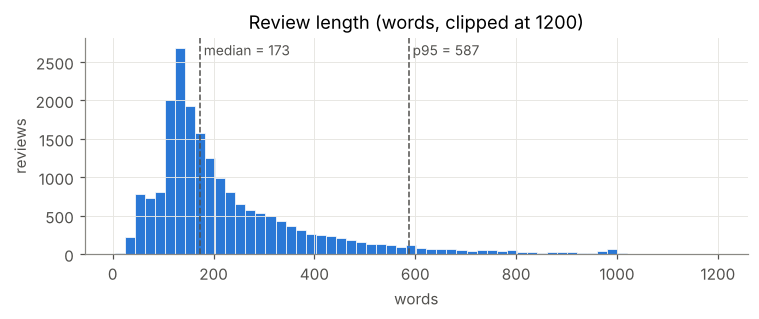

In [3]:
lengths = train_df["text"].str.split().str.len()
p50, p90, p95 = np.percentile(lengths, [50, 90, 95])
print(f"words per review  median={p50:.0f}  p90={p90:.0f}  p95={p95:.0f}  max={lengths.max()}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(lengths.clip(upper=1200), bins=60, color="#2a78d6", edgecolor="#fcfcfb", linewidth=0.5)
for v, lab in [(p50, "median"), (p95, "p95")]:
    ax.axvline(v, color="#52514e", lw=1, ls="--")
    ax.text(v, ax.get_ylim()[1]*0.92, f" {lab} = {v:.0f}", color="#52514e", fontsize=9)
ax.set(title="Review length (words, clipped at 1200)", xlabel="words", ylabel="reviews")
plt.tight_layout(); plt.show()

## 2. Tokenize and vectorize

Neural networks work on numbers, not strings. `TextVectorization` does three things:

1. **Standardize.** Lowercase the text, remove the `<br />` HTML tags IMDB reviews contain, and strip punctuation except apostrophes, so *don't* stays one token.
2. **Tokenize.** Split on whitespace.
3. **Index.** Map each token to an integer id. Ids are ordered by frequency, so id 2 is the most common word. Id 0 is reserved for padding and id 1 for `[UNK]` (any word outside the vocabulary).

Two choices matter here:
- **`VOCAB_SIZE = 20,000`.** Words outside the top 20k are rare. They get too few gradient updates to learn meaningful vectors, so mapping them to `[UNK]` loses little.
- **`SEQ_LEN = 400`.** This is roughly the p90 length: about 90% of reviews fit completely, and the long tail gets truncated.

The vectorizer is `adapt`-ed on the **training split only**, so test-set vocabulary does not leak into the model.

In [4]:
VOCAB_SIZE = 20_000
SEQ_LEN    = 400

def standardize(text):
    text = tf.strings.lower(text)
    text = tf.strings.regex_replace(text, r"<br\s*/?>", " ")
    text = tf.strings.regex_replace(text, r"[^a-z0-9' ]", " ")   # keep letters, digits, apostrophes
    text = tf.strings.regex_replace(text, r"(^|\s)'+|'+(\s|$)", " ")  # drop quote-style apostrophes
    return text

vectorizer = layers.TextVectorization(max_tokens=VOCAB_SIZE, standardize=standardize,
                                      output_mode="int", output_sequence_length=SEQ_LEN)
t0 = time.time()
vectorizer.adapt(tf.data.Dataset.from_tensor_slices(train_df["text"].values).batch(512))
vocab = vectorizer.get_vocabulary()
word2id = {w: i for i, w in enumerate(vocab)}
print(f"adapted in {time.time()-t0:.1f}s | vocab size = {len(vocab):,}")
print("first 15 ids:", vocab[:15])

sample = train_df["text"].iloc[0][:160]
ids = vectorizer([sample]).numpy()[0]
print("\nraw     :", sample)
print("ids     :", ids[:25], "...")
print("decoded :", " ".join(vocab[i] for i in ids[:25] if i != 0))

adapted in 1.4s | vocab size = 20,000
first 15 ids: ['', '[UNK]', np.str_('the'), np.str_('and'), np.str_('a'), np.str_('of'), np.str_('to'), np.str_('is'), np.str_('in'), np.str_('it'), np.str_('i'), np.str_('this'), np.str_('that'), np.str_('was'), np.str_('as')]

raw     : REIGN OVER ME (2007) *** Adam Sandler, Don Cheadle, Jada Pinkett-Smith, Liv Tyler, Saffron Burrows, Donald Sutherland, Robert Klein, Melinda Dillon, Mike Binder
ids     : [ 5336   121    68  4366  2082  4008  1369  7833 11368 13564  1549  6629
  4444     1 18948  2551  3675   614  8649  9253  6193  2012 17870     0
     0] ...
decoded : reign over me 2007 adam sandler don cheadle jada pinkett smith liv tyler [UNK] burrows donald sutherland robert klein melinda dillon mike binder


In [5]:
BATCH = 256
AUTOTUNE = tf.data.AUTOTUNE

def make_ds(df, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((df["text"].values, df["label"].values.astype("float32")))
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED)
    # vectorize once inside the tf.data pipeline -> the model receives integer ids
    return ds.batch(BATCH).map(lambda x, y: (vectorizer(x), y), num_parallel_calls=AUTOTUNE).cache().prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)
xb = vectorizer(train_df["text"].values[:BATCH])
print("batch shape:", tuple(xb.shape), "| share of padding ids in a batch:", round(float(tf.reduce_mean(tf.cast(xb == 0, tf.float32))), 3))

batch shape: (256, 400) | share of padding ids in a batch: 0.452


## 3. Train a Keras classifier with an `Embedding` layer

**Architecture, and why it is this simple**

```
token ids (400) → Embedding(20000 → 64, mask_zero) → GlobalAveragePooling1D → Dense(16, relu) → Dropout → Dense(1, sigmoid)
```

- The **`Embedding` layer** is a lookup table of shape `20000 × 64`. Row *i* is the vector for word *i*. It begins random and is updated by backpropagation like any other weight.
- **`mask_zero=True`** tells the pooling layer to ignore padding, so short reviews are not diluted by zeros.
- **`GlobalAveragePooling1D`** averages the word vectors of a review into a single 64-d vector. This is deliberate. With an order-free average, the *only* way the model can separate positive from negative reviews is by placing sentiment-bearing words in different regions of the embedding space. Everything the model knows ends up in the embeddings, which is exactly what we want to inspect afterwards. An LSTM or Transformer would probably score a little higher, but it would spread the knowledge across recurrent or attention weights.

Loss is binary cross-entropy and the optimizer is Adam. `EarlyStopping` on validation loss restores the best epoch, which prevents the embeddings from over-fitting rare words.

In [6]:
EMBED_DIM = 64

def build_classifier(embedding_layer):
    inp = keras.Input(shape=(SEQ_LEN,), dtype="int64", name="token_ids")
    x = embedding_layer(inp)
    x = layers.GlobalAveragePooling1D(name="avg_pool")(x)
    x = layers.Dense(16, activation="relu", name="dense")(x)
    x = layers.Dropout(0.3, name="dropout")(x)
    out = layers.Dense(1, activation="sigmoid", name="output")(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return m

model = build_classifier(layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True, name="embedding"))
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ token_ids           │ (None, 400)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 400, 64)   │  1,280,000 │ token_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 400)       │          0 │ token_ids[0][0]   │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ avg_pool            │ (None, 64)        │          0 │ embedding[0][0],  │
│ (GlobalAveragePool… │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │      1,040 │ avg_pool[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 16)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 1)         │         17 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,281,057 (4.89 MB)

 Trainable params: 1,281,057 (4.89 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=[early], verbose=2)
print(f"trained in {time.time()-t0:.0f}s, best epoch = {int(np.argmin(history.history['val_loss'])) + 1}")

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


79/79 - 5s - 64ms/step - accuracy: 0.6636 - loss: 0.6631 - val_accuracy: 0.7790 - val_loss: 0.5974


Epoch 2/20


79/79 - 3s - 39ms/step - accuracy: 0.8137 - loss: 0.5014 - val_accuracy: 0.8488 - val_loss: 0.4123


...

Epoch 7/20


79/79 - 3s - 33ms/step - accuracy: 0.9462 - loss: 0.1662 - val_accuracy: 0.8834 - val_loss: 0.2919


Epoch 8/20


79/79 - 5s - 68ms/step - accuracy: 0.9567 - loss: 0.1399 - val_accuracy: 0.8832 - val_loss: 0.2987


trained in 34s, best epoch = 6


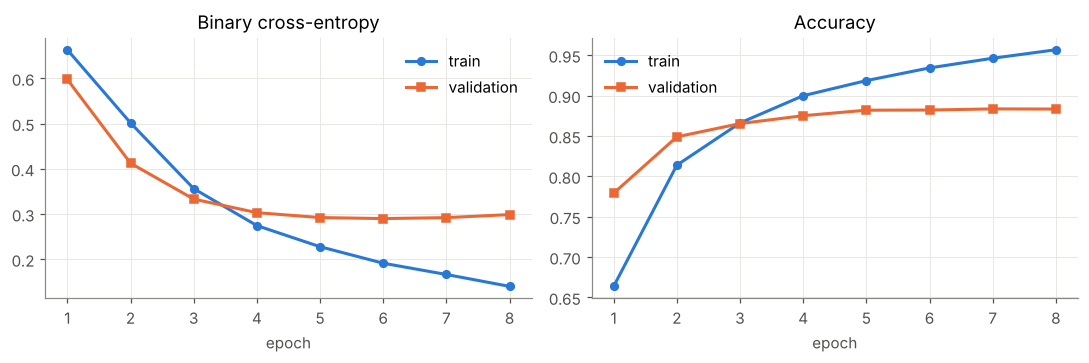

Keras-embedding model  →  TEST accuracy = 0.8918   loss = 0.2672


In [8]:
h = history.history
ep = np.arange(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, key, title in [(axes[0], "loss", "Binary cross-entropy"), (axes[1], "accuracy", "Accuracy")]:
    ax.plot(ep, h[key], color="#2a78d6", lw=2, marker="o", ms=5, label="train")
    ax.plot(ep, h["val_" + key], color="#eb6834", lw=2, marker="s", ms=5, label="validation")
    ax.set(title=title, xlabel="epoch"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Keras-embedding model  →  TEST accuracy = {test_acc:.4f}   loss = {test_loss:.4f}")

## 4. Extract the learned word embeddings

After training, the `Embedding` layer's weight matrix *is* the set of word vectors: row `word2id[w]` is the 64-d vector for `w`. Rows 0 (padding) and 1 (`[UNK]`) are not real words, so we exclude them from the analysis.

We also export `vectors.tsv` / `metadata.tsv`, which can be dropped into [projector.tensorflow.org](https://projector.tensorflow.org) for interactive 3-D exploration.

In [9]:
keras_E = model.get_layer("embedding").get_weights()[0]       # shape (VOCAB_SIZE, EMBED_DIM)
print("Keras embedding matrix:", keras_E.shape)

def keras_vec(word):
    return keras_E[word2id[word]]

print("vector for 'excellent' (first 8 dims):", np.round(keras_vec("excellent")[:8], 3))
print("L2 norms  good / the / excellent / awful:",
      [round(float(np.linalg.norm(keras_vec(w))), 2) for w in ["good", "the", "excellent", "awful"]])

os.makedirs("embeddings_export", exist_ok=True)
with open("embeddings_export/vectors.tsv", "w") as fv, open("embeddings_export/metadata.tsv", "w") as fm:
    for i in range(2, len(vocab)):
        fv.write("\t".join(f"{v:.5f}" for v in keras_E[i]) + "\n"); fm.write(vocab[i] + "\n")
print("exported", len(vocab) - 2, "vectors to embeddings_export/")

Keras embedding matrix: (20000, 64)
vector for 'excellent' (first 8 dims): [ 0.612  0.631  0.287  0.616  0.554  0.602  0.499 -0.569]
L2 norms  good / the / excellent / awful: [1.26, 1.34, 4.43, 6.0]


exported 19998 vectors to embeddings_export/


### 4.1 What did the embedding actually learn? Checking against the raw data

The norms above look strange at first: *excellent* (4.4) and *awful* (6.3) are large, while *good* (~1.3) is about the same size as *the*. **Hypothesis:** the model only grows a vector when the word helps separate the classes. *good* shows up in both positive and negative reviews ("not good", "good actors, terrible film"), so it isn't very diagnostic.

We can test that without the model. For each frequent word we compute its **document-level log-odds** of appearing in a positive versus a negative review, straight from the training labels:

$$\text{log-odds}(w) = \log\frac{P(w \mid \text{pos})}{P(w \mid \text{neg})}$$

Then we check two things:
- (a) Does the vector norm track |log-odds|?
- (b) Does the main direction of the embedding matrix track the signed log-odds?

In [10]:
from scipy.sparse import csr_matrix
train_ids = np.concatenate([vectorizer(train_df["text"].values[i:i+2000]).numpy()
                            for i in range(0, len(train_df), 2000)])
rows = np.repeat(np.arange(train_ids.shape[0]), train_ids.shape[1])
doc_term = csr_matrix((np.ones(train_ids.size, dtype=np.int8), (rows, train_ids.ravel())),
                      shape=(train_ids.shape[0], VOCAB_SIZE))
doc_term.data[:] = 1                                   # presence, not counts
y_train = train_df["label"].values
df_pos = np.asarray(doc_term[y_train == 1].sum(0)).ravel()
df_neg = np.asarray(doc_term[y_train == 0].sum(0)).ravel()
n_pos, n_neg = (y_train == 1).sum(), (y_train == 0).sum()
log_odds = np.log((df_pos + 1) / (n_pos + 2)) - np.log((df_neg + 1) / (n_neg + 2))   # Laplace-smoothed

ids10k = np.arange(2, 10_000)
norms = np.linalg.norm(keras_E[ids10k], axis=1)
pc1_all = PCA(n_components=1, random_state=SEED).fit(keras_E[ids10k])
proj = pc1_all.transform(keras_E[ids10k]).ravel()
r_norm, _ = spearmanr(norms, np.abs(log_odds[ids10k]))
r_dir, _ = spearmanr(proj, log_odds[ids10k])
print(f"(a) Spearman(norm, |log-odds|)            = {r_norm:+.3f}   over {len(ids10k):,} frequent words")
print(f"(b) Spearman(PC1 projection, log-odds)     = {r_dir:+.3f}   (sign of PC1 is arbitrary)")
print(f"    PC1 of the full 10k-word matrix explains {pc1_all.explained_variance_ratio_[0]:.0%} of variance")

probe_words = ["good", "the", "excellent", "awful", "great", "bad", "movie", "actor", "plot", "script", "story", "film"]
pd.DataFrame({
    "P(positive | word in review)": [df_pos[word2id[w]] / (df_pos[word2id[w]] + df_neg[word2id[w]]) for w in probe_words],
    "log-odds": [log_odds[word2id[w]] for w in probe_words],
    "embedding norm": [np.linalg.norm(keras_vec(w)) for w in probe_words],
    "reviews containing it": [df_pos[word2id[w]] + df_neg[word2id[w]] for w in probe_words],
}, index=probe_words).round(3)

(a) Spearman(norm, |log-odds|)            = +0.461   over 9,998 frequent words
(b) Spearman(PC1 projection, log-odds)     = -0.771   (sign of PC1 is arbitrary)
    PC1 of the full 10k-word matrix explains 90% of variance


,P(positive | word in review),log-odds,embedding norm,reviews containing it
good,0.492,-0.030,1.259,7263
the,0.500,-0.002,1.339,19824
excellent,0.797,1.365,4.425,1355
awful,0.088,-2.328,5.999,1067
great,0.676,0.734,3.917,4800
bad,0.248,-1.106,4.459,4536
movie,0.458,-0.169,1.177,12070
actor,0.500,0.000,1.029,1410
plot,0.364,-0.560,1.707,3810
script,0.326,-0.725,2.532,1837


## 5. Cosine similarity between selected words (Keras embeddings)

**Why cosine?** It compares the *direction* of two vectors and ignores their length:

$$\cos(\mathbf{a},\mathbf{b}) = \frac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert\,\lVert\mathbf{b}\rVert} \in [-1, 1]$$

As we just saw, length mostly encodes *how strongly* a word matters, so direction is the cleaner signal for *what* a word means to the model. +1 means the same direction, 0 means unrelated (orthogonal), and −1 means opposite.

**Word selection.** There are 24 words in three groups of 8, chosen so that every hypothesis has test cases:
- **positive** sentiment words
- **negative** sentiment words
- **neutral** movie-domain words that carry no sentiment

We implement cosine by hand with NumPy, then check it against scikit-learn.

In [11]:
WORD_GROUPS = {
    "positive": ["good", "great", "excellent", "wonderful", "amazing", "brilliant", "best", "love"],
    "negative": ["bad", "awful", "terrible", "boring", "worst", "waste", "horrible", "poor"],
    "neutral":  ["movie", "film", "actor", "actress", "plot", "director", "scene", "story"],
}
WORDS = [w for g in WORD_GROUPS.values() for w in g]
GROUP_OF = {w: g for g, ws in WORD_GROUPS.items() for w in ws}
missing = [w for w in WORDS if w not in word2id]
print("all selected words in Keras vocab:", not missing, missing or "")

def cosine(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))

def cosine_matrix(M):
    Mn = M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-12)
    return Mn @ Mn.T

keras_sel = np.stack([keras_vec(w) for w in WORDS])
keras_S = cosine_matrix(keras_sel)
assert np.allclose(keras_S, sk_cosine(keras_sel), atol=1e-5)   # sanity check vs sklearn
print("manual cosine matches sklearn ✔")

all selected words in Keras vocab: True 
manual cosine matches sklearn ✔


**Pairs of interest.** Synonyms should be close. Antonyms are the key test. Domain pairs (*movie/film*, *actor/actress*) check whether the model learned anything beyond sentiment.

In [12]:
PAIRS = [
    ("good", "great", "synonym"), ("excellent", "wonderful", "synonym"), ("bad", "awful", "synonym"),
    ("terrible", "horrible", "synonym"),
    ("good", "bad", "antonym"), ("excellent", "terrible", "antonym"), ("best", "worst", "antonym"),
    ("love", "waste", "antonym"),
    ("movie", "film", "domain"), ("actor", "actress", "domain"), ("plot", "story", "domain"),
    ("movie", "excellent", "cross"), ("movie", "awful", "cross"),
]
pair_df = pd.DataFrame([(a, b, kind, cosine(keras_vec(a), keras_vec(b))) for a, b, kind in PAIRS],
                       columns=["word_a", "word_b", "relation", "keras_cos"])
pair_df.style.format({"keras_cos": "{:+.3f}"}).background_gradient(subset=["keras_cos"], cmap="RdBu", vmin=-1, vmax=1)

,word_a,word_b,relation,keras_cos
0,good,great,synonym,+0.966
1,excellent,wonderful,synonym,+0.996
2,bad,awful,synonym,+0.984
3,terrible,horrible,synonym,+0.998
4,good,bad,antonym,-0.869
5,excellent,terrible,antonym,-0.990
6,best,worst,antonym,-0.972
7,love,waste,antonym,-0.967
8,movie,film,domain,+0.834
9,actor,actress,domain,+0.934


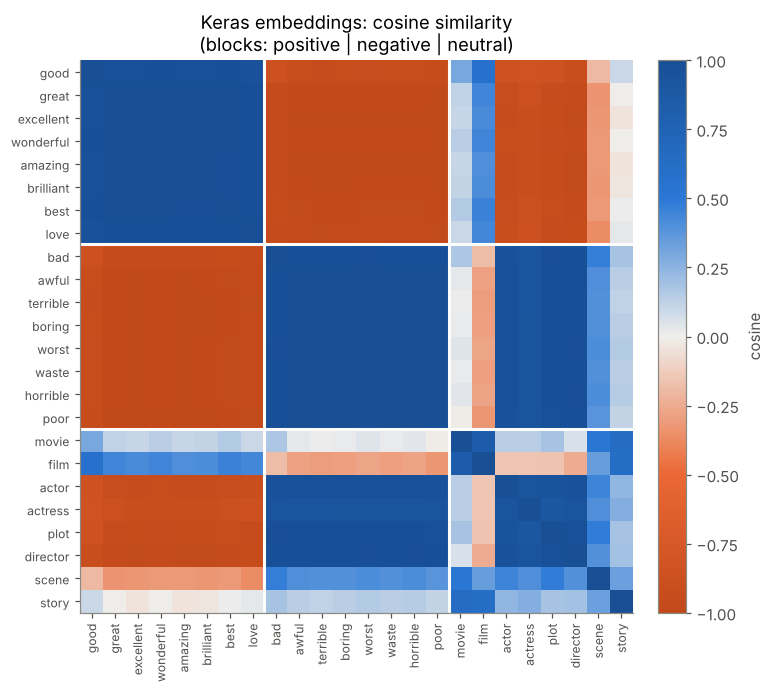

In [13]:
from matplotlib.colors import LinearSegmentedColormap
# diverging map: orange (−1) → neutral gray (0) → blue (+1)
DIVERGING = LinearSegmentedColormap.from_list("div", ["#c2491a", "#eb6834", "#f0efec", "#2a78d6", "#184f95"])

def plot_sim_heatmap(S, title, ax):
    im = ax.imshow(S, cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(len(WORDS))); ax.set_yticks(range(len(WORDS)))
    ax.set_xticklabels(WORDS, rotation=90, fontsize=8); ax.set_yticklabels(WORDS, fontsize=8)
    ax.grid(False)
    for k in (8, 16):                                    # group separators
        ax.axhline(k - .5, color="#fcfcfb", lw=2); ax.axvline(k - .5, color="#fcfcfb", lw=2)
    ax.set_title(title)
    return im

fig, ax = plt.subplots(figsize=(7.2, 6.4))
im = plot_sim_heatmap(keras_S, "Keras embeddings: cosine similarity\n(blocks: positive | negative | neutral)", ax)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="cosine")
plt.tight_layout(); plt.show()

In [14]:
def group_block_means(S):
    # mean cosine within/between groups (diagonal excluded)
    out = {}
    names = list(WORD_GROUPS)
    for i, gi in enumerate(names):
        for gj in names[i:]:
            ii = [WORDS.index(w) for w in WORD_GROUPS[gi]]; jj = [WORDS.index(w) for w in WORD_GROUPS[gj]]
            block = S[np.ix_(ii, jj)]
            vals = block[~np.eye(len(ii), dtype=bool)] if gi == gj else block.ravel()
            out[f"{gi} ↔ {gj}"] = vals.mean()
    return pd.Series(out)

keras_blocks = group_block_means(keras_S)
keras_blocks.to_frame("keras_mean_cos").round(3)

,keras_mean_cos
positive ↔ positive,0.983
positive ↔ negative,-0.970
positive ↔ neutral,-0.425
negative ↔ negative,0.994
negative ↔ neutral,0.520
neutral ↔ neutral,0.405


**Nearest neighbours.** The 24×24 matrix only covers words we picked ourselves. Nearest neighbours let the embedding space speak for itself. The search is restricted to the 10,000 most frequent tokens, because very rare words received few updates and their vectors are mostly noise.

In [15]:
TOPK_CANDIDATES = 10_000
cand_ids = np.arange(2, TOPK_CANDIDATES)                      # skip PAD and [UNK]
cand_words = [vocab[i] for i in cand_ids]
keras_cand = keras_E[cand_ids]
keras_cand_n = keras_cand / (np.linalg.norm(keras_cand, axis=1, keepdims=True) + 1e-12)

def keras_neighbors(word, k=8):
    q = keras_vec(word); q = q / np.linalg.norm(q)
    sims = keras_cand_n @ q
    order = [i for i in np.argsort(-sims) if cand_words[i] != word][:k]
    return [(cand_words[i], round(float(sims[i]), 2)) for i in order]

QUERY = ["excellent", "awful", "boring", "movie", "actor", "plot"]
pd.DataFrame({q: [f"{w} ({s})" for w, s in keras_neighbors(q)] for q in QUERY})

,excellent,awful,boring,movie,actor,plot
0,amazing (1.0),terrible (1.0),worst (1.0),to (0.96),line (0.97),bad (0.99)
1,perfect (1.0),waste (1.0),waste (1.0),the (0.94),care (0.97),script (0.98)
2,superb (1.0),worst (1.0),terrible (1.0),this (0.94),wooden (0.97),money (0.98)
3,wonderful (1.0),horrible (1.0),awful (1.0),that (0.92),worst (0.97),1 (0.98)
4,fantastic (1.0),pointless (1.0),horrible (1.0),a (0.92),looks (0.97),crap (0.98)
5,enjoyed (1.0),boring (1.0),stupid (1.0),i (0.92),horrible (0.97),least (0.98)
6,great (1.0),stupid (1.0),pointless (1.0),one (0.9),avoid (0.97),avoid (0.98)
7,gem (1.0),nothing (1.0),poor (1.0),they (0.89),crap (0.97),off (0.98)


## 6. Visualize the Keras embeddings in 2-D

**Why PCA?** It is deterministic and linear, and its axes are directions of maximum variance, so they can be interpreted. That lets us ask *what the main axis of variation in this space means*. t-SNE and UMAP can make prettier clusters, but on 24 points they are unstable from run to run, and the distances between clusters are not meaningful.

PCA is fitted on the 24 selected words. The **explained-variance ratio** tells us how faithful the 2-D picture is.

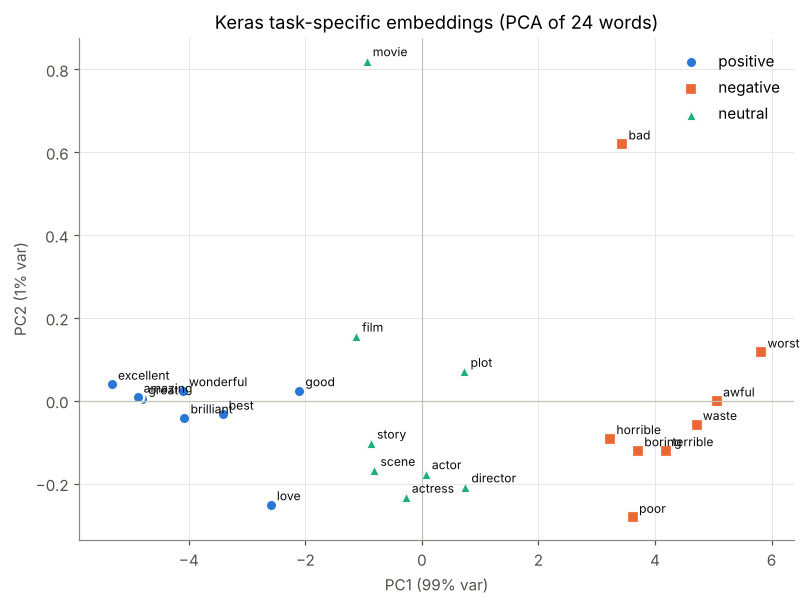

mean PC1 by group: {'negative': 4.230000019073486, 'neutral': -0.3100000023841858, 'positive': -3.9100000858306885}


In [16]:
def plot_pca(M, title, ax):
    pca = PCA(n_components=2, random_state=SEED)
    Z = pca.fit_transform(M)
    for g, st in GROUP_STYLE.items():
        idx = [i for i, w in enumerate(WORDS) if GROUP_OF[w] == g]
        ax.scatter(Z[idx, 0], Z[idx, 1], s=55, label=g, edgecolor="#fcfcfb", linewidth=1.5, **st)
    for i, w in enumerate(WORDS):
        ax.annotate(w, Z[i], xytext=(4, 3), textcoords="offset points", fontsize=8, color="#0b0b0b")
    ev = pca.explained_variance_ratio_
    ax.set(title=title, xlabel=f"PC1 ({ev[0]:.0%} var)", ylabel=f"PC2 ({ev[1]:.0%} var)")
    ax.axhline(0, color="#c3c2b7", lw=0.8); ax.axvline(0, color="#c3c2b7", lw=0.8)
    ax.legend(frameon=False, loc="best")
    return Z, ev

fig, ax = plt.subplots(figsize=(7.5, 5.6))
keras_Z, keras_ev = plot_pca(keras_sel, "Keras task-specific embeddings (PCA of 24 words)", ax)
plt.tight_layout(); plt.show()

pc1_by_group = pd.Series(keras_Z[:, 0]).groupby([GROUP_OF[w] for w in WORDS]).mean()
print("mean PC1 by group:", pc1_by_group.round(2).to_dict())

## 7. Load the pretrained Word2Vec model

**`word2vec-google-news-300`** (Mikolov et al., 2013) contains 3M words and phrases with 300 dimensions each. It was trained on roughly 100B tokens of Google News using the skip-gram objective: given a word, predict the words around it. Its notion of similarity is therefore **distributional**. Two words are similar if they appear in similar contexts, whatever their sentiment.

`gensim.downloader` fetches the file (about 1.6 GB, once) and caches it in `~/gensim-data`. To save RAM we load only the 1M most frequent entries, which is enough to cover our vocabulary. The full model needs about 3.6 GB.

Two practical differences from our Keras vocabulary:
- Word2Vec is **case-sensitive** and was trained on news text. Lookups try the lowercase form first, then Title-case.
- Some stop-words (*a*, *and*, *of*) were dropped from its vocabulary during training.

In [17]:
import gensim.downloader as api
from gensim.models import KeyedVectors

W2V_LIMIT = 1_000_000
t0 = time.time()
w2v_path = api.load("word2vec-google-news-300", return_path=True)   # downloads once, then cached
w2v = KeyedVectors.load_word2vec_format(w2v_path, binary=True, limit=W2V_LIMIT)
print(f"loaded {len(w2v.index_to_key):,} vectors × {w2v.vector_size} dims in {time.time()-t0:.0f}s")

def w2v_key(word):
    for cand in (word, word.capitalize()):
        if cand in w2v.key_to_index:
            return cand
    return None

print("selected words missing from Word2Vec:", [w for w in WORDS if w2v_key(w) is None] or "none")

loaded 1,000,000 vectors × 300 dims in 13s
selected words missing from Word2Vec: none


## 8. Repeat the similarity and visualization analysis with Word2Vec

Same 24 words, same pairs, same heatmap, same PCA. Only the vectors change.

In [18]:
w2v_sel = np.stack([w2v[w2v_key(w)] for w in WORDS])
w2v_S = cosine_matrix(w2v_sel)
assert np.isclose(w2v_S[WORDS.index("good"), WORDS.index("bad")], w2v.similarity("good", "bad"), atol=1e-5)
print("manual cosine matches gensim.similarity ✔")

pair_df["w2v_cos"] = [cosine(w2v[w2v_key(a)], w2v[w2v_key(b)]) for a, b, _ in PAIRS]
pair_df["difference (keras − w2v)"] = pair_df["keras_cos"] - pair_df["w2v_cos"]
pair_df.style.format({c: "{:+.3f}" for c in ["keras_cos", "w2v_cos", "difference (keras − w2v)"]}) \
       .background_gradient(subset=["keras_cos", "w2v_cos"], cmap="RdBu", vmin=-1, vmax=1)

manual cosine matches gensim.similarity ✔


,word_a,word_b,relation,keras_cos,w2v_cos,difference (keras − w2v)
0,good,great,synonym,+0.966,+0.729,+0.237
1,excellent,wonderful,synonym,+0.996,+0.561,+0.435
2,bad,awful,synonym,+0.984,+0.553,+0.431
3,terrible,horrible,synonym,+0.998,+0.924,+0.073
4,good,bad,antonym,-0.869,+0.719,-1.588
5,excellent,terrible,antonym,-0.990,+0.330,-1.320
6,best,worst,antonym,-0.972,+0.584,-1.556
7,love,waste,antonym,-0.967,+0.122,-1.090
8,movie,film,domain,+0.834,+0.868,-0.034
9,actor,actress,domain,+0.934,+0.793,+0.141


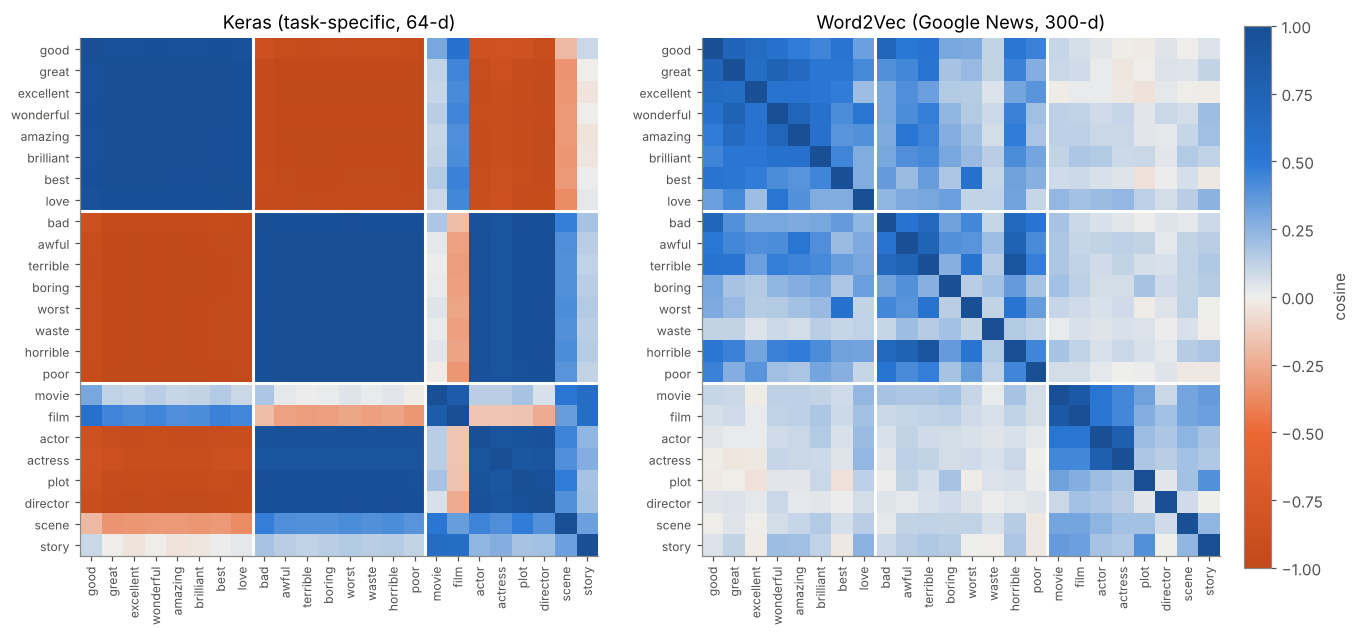

,keras_mean_cos,w2v_mean_cos
positive ↔ positive,0.983,0.505
positive ↔ negative,-0.970,0.306
positive ↔ neutral,-0.425,0.077
negative ↔ negative,0.994,0.398
negative ↔ neutral,0.520,0.080
neutral ↔ neutral,0.405,0.292


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
plot_sim_heatmap(keras_S, "Keras (task-specific, 64-d)", axes[0])
im = plot_sim_heatmap(w2v_S, "Word2Vec (Google News, 300-d)", axes[1])
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, label="cosine")
plt.show()

w2v_blocks = group_block_means(w2v_S)
pd.DataFrame({"keras_mean_cos": keras_blocks, "w2v_mean_cos": w2v_blocks}).round(3)

In [20]:
def w2v_neighbors_global(word, k=8):
    return [(w, round(float(s), 2)) for w, s in w2v.most_similar(w2v_key(word), topn=k)]

print("Word2Vec neighbours over its FULL vocabulary (note phrases, misspellings, casing variants):")
pd.DataFrame({q: [f"{w} ({s})" for w, s in w2v_neighbors_global(q)] for q in QUERY})

Word2Vec neighbours over its FULL vocabulary (note phrases, misspellings, casing variants):


,excellent,awful,boring,movie,actor,plot
0,terrific (0.74),horrible (0.76),dull (0.74),film (0.87),actress (0.79),plots (0.76)
1,superb (0.71),terrible (0.75),uninteresting (0.7),movies (0.8),Actor (0.74),Plot (0.65)
2,exceptional (0.68),dreadful (0.72),monotonous (0.68),films (0.74),thesp (0.7),plotting (0.63)
3,fantastic (0.68),horrendous (0.7),bored (0.65),Movie (0.67),thespian (0.67),plotted (0.6)
4,good (0.64),horrid (0.67),bland (0.63),horror_flick (0.66),actors (0.65),plotline (0.59)
5,great (0.61),atrocious (0.66),tedious (0.63),sequel (0.66),funnyman (0.64),plotters (0.54)
6,Excellent (0.61),ugly (0.62),unexciting (0.62),romantic_comedy (0.64),entertainer (0.62),storyline (0.53)
7,impeccable (0.6),lousy (0.61),tiresome (0.61),flick (0.63),Shakespearean_actor (0.61),convoluted_plot (0.52)


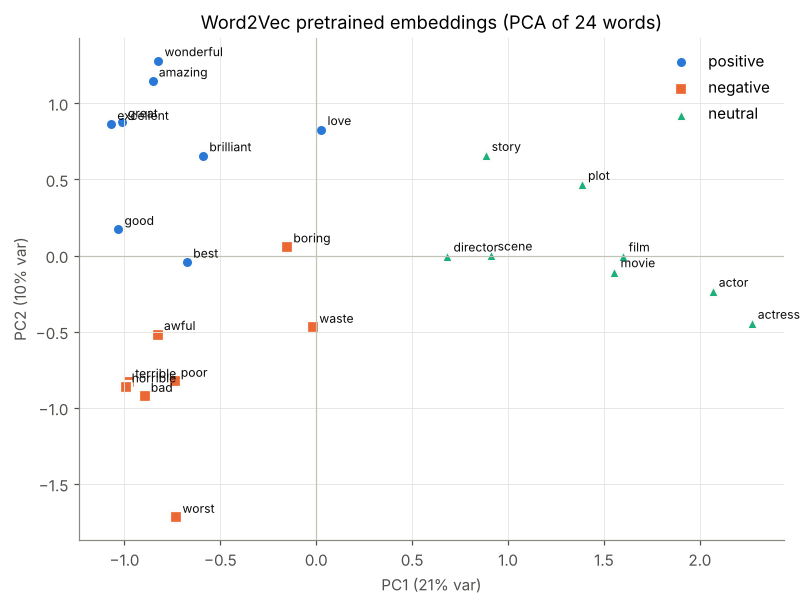

mean PC1 by group: {'negative': -0.6700000166893005, 'neutral': 1.4199999570846558, 'positive': -0.75}


In [21]:
fig, ax = plt.subplots(figsize=(7.5, 5.6))
w2v_Z, w2v_ev = plot_pca(w2v_sel, "Word2Vec pretrained embeddings (PCA of 24 words)", ax)
plt.tight_layout(); plt.show()
print("mean PC1 by group:", pd.Series(w2v_Z[:, 0]).groupby([GROUP_OF[w] for w in WORDS]).mean().round(2).to_dict())

## 9. Compare task-specific Keras embeddings with pretrained Word2Vec

Side-by-side pictures are suggestive, but the comparison should rest on numbers. Five measurements follow:

1. **2-D layouts side by side**, with explained variance.
2. **Agreement of the similarity structures.** Spearman correlation between the two 24×24 similarity matrices (upper triangles).
3. **Neighbour overlap.** For frequent words, how many of the top-10 neighbours do the two spaces share when both search the *same* candidate set?
4. **Analogies.** Do the classic vector-arithmetic regularities exist in either space?
5. **Downstream utility.** Plug frozen Word2Vec vectors into the *same* classifier and compare test accuracy. This is the real test of which embedding is better *for this task*.

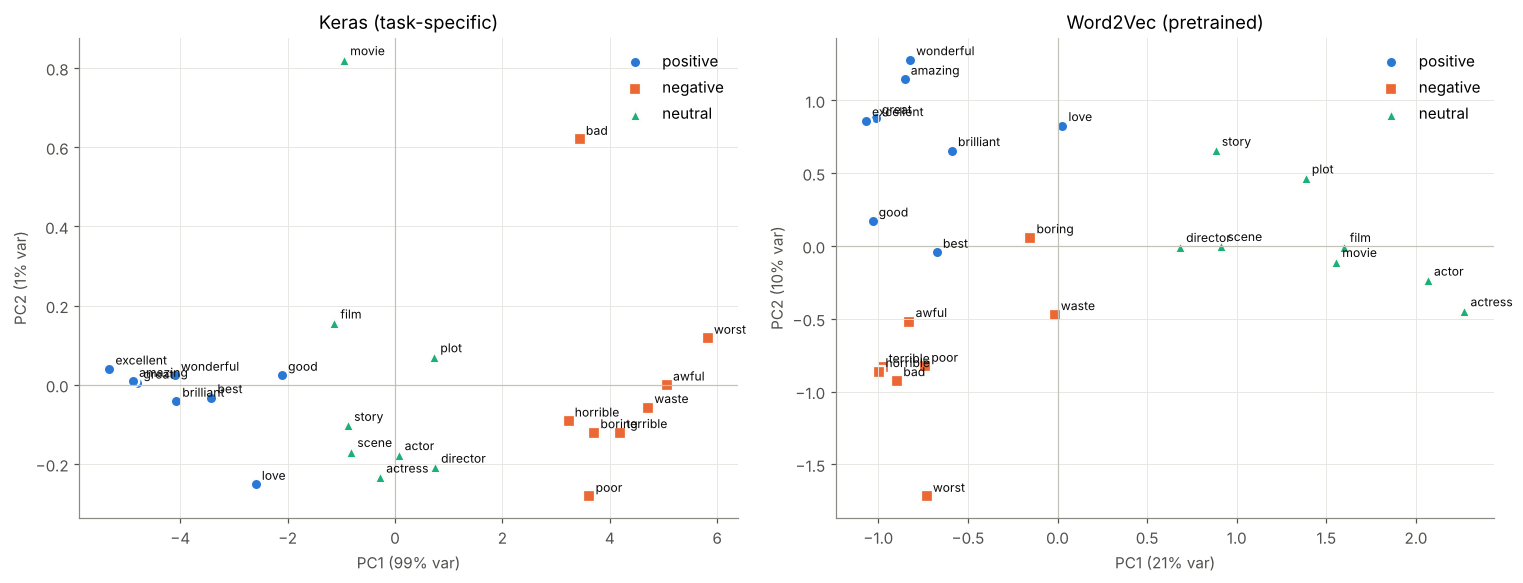

PC1+PC2 explained variance → Keras 100% (PC1 99%) | Word2Vec 31% (PC1 21%)
Spearman ρ between the two similarity matrices (276 word pairs): 0.117  (p=5.2e-02)


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
plot_pca(keras_sel, "Keras (task-specific)", axes[0])
plot_pca(w2v_sel, "Word2Vec (pretrained)", axes[1])
plt.tight_layout(); plt.show()

iu = np.triu_indices(len(WORDS), k=1)
rho, pval = spearmanr(keras_S[iu], w2v_S[iu])
print(f"PC1+PC2 explained variance → Keras {keras_ev.sum():.0%} (PC1 {keras_ev[0]:.0%}) | "
      f"Word2Vec {w2v_ev.sum():.0%} (PC1 {w2v_ev[0]:.0%})")
print(f"Spearman ρ between the two similarity matrices ({len(iu[0])} word pairs): {rho:.3f}  (p={pval:.1e})")

In [23]:
# Neighbour overlap on a shared candidate pool: frequent Keras-vocab words that also exist in Word2Vec
pool = [(i, w) for i, w in zip(cand_ids, cand_words) if w2v_key(w) is not None and w.isalpha()]
pool_words = [w for _, w in pool]
Pk = keras_E[[i for i, _ in pool]];                Pk /= np.linalg.norm(Pk, axis=1, keepdims=True) + 1e-12
Pw = np.stack([w2v[w2v_key(w)] for w in pool_words]); Pw /= np.linalg.norm(Pw, axis=1, keepdims=True)
pool_index = {w: j for j, w in enumerate(pool_words)}
print(f"shared candidate pool: {len(pool_words):,} words")

def topk(P, word, k=10):
    sims = P @ P[pool_index[word]]
    sims[pool_index[word]] = -np.inf
    return set(np.argsort(-sims)[:k])

probe = pool_words[50:1050]          # 1,000 frequent content-ish words (skip the very top stop-words)
overlaps = np.array([len(topk(Pk, w) & topk(Pw, w)) / 10 for w in probe])
chance = 10 / (len(pool_words) - 1)
print(f"mean top-10 neighbour overlap over {len(probe)} words: {overlaps.mean():.3f}  "
      f"(random baseline ≈ {chance:.4f})")
rows = []
for q in QUERY:
    a, b = topk(Pk, q), topk(Pw, q)
    rows.append({"word": q,
                 "keras top-5": ", ".join(pool_words[j] for j in sorted(a, key=lambda j: -(Pk[j] @ Pk[pool_index[q]]))[:5]),
                 "w2v top-5":   ", ".join(pool_words[j] for j in sorted(b, key=lambda j: -(Pw[j] @ Pw[pool_index[q]]))[:5]),
                 "shared@10": len(a & b)})
pd.DataFrame(rows)

shared candidate pool: 9,641 words


mean top-10 neighbour overlap over 1000 words: 0.009  (random baseline ≈ 0.0010)


,word,keras top-5,w2v top-5,shared@10
0,excellent,"amazing, perfect, superb, wonderful, fantastic","terrific, superb, exceptional, fantastic, good",3
1,awful,"terrible, waste, worst, horrible, pointless","horrible, terrible, dreadful, horrendous, horrid",2
2,boring,"worst, waste, terrible, awful, horrible","dull, uninteresting, monotonous, bored, bland",2
3,movie,"to, the, this, that, a","film, movies, films, sequel, flick",0
4,actor,"line, care, wooden, worst, looks","actress, actors, entertainer, comedian, screen...",0
5,plot,"bad, script, money, crap, least","plots, plotting, plotted, storyline, conspiracy",0


In [24]:
def analogy_keras(a, b, c, k=5):
    # a − b + c over the frequent candidate pool, excluding the inputs
    v = keras_vec(a) - keras_vec(b) + keras_vec(c); v /= np.linalg.norm(v)
    sims = keras_cand_n @ v
    return [cand_words[i] for i in np.argsort(-sims) if cand_words[i] not in (a, b, c)][:k]

# (keras words, word2vec words) — Word2Vec is case-sensitive, so proper nouns get their natural casing there
ANALOGIES = [(("king", "man", "woman"),    ("king", "man", "woman")),
             (("actor", "man", "woman"),   ("actor", "man", "woman")),
             (("good", "best", "worst"),   ("good", "best", "worst")),
             (("paris", "france", "italy"), ("paris", "france", "italy")),     # lowercase: what our pipeline produces
             (("paris", "france", "italy"), ("Paris", "France", "Italy"))]     # correct casing for Word2Vec
rows = []
for (a, b, c), (wa, wb, wc) in ANALOGIES:
    w2v_ans = [w for w, _ in w2v.most_similar(positive=[wa, wc], negative=[wb], topn=5)]
    rows.append({"analogy (keras | w2v input)": f"{a} − {b} + {c}  |  {wa} − {wb} + {wc}",
                 "keras top-5": ", ".join(analogy_keras(a, b, c)), "word2vec top-5": ", ".join(w2v_ans)})
pd.DataFrame(rows)

,analogy (keras | w2v input),keras top-5,word2vec top-5
0,king − man + woman | king − man + woman,"wagner, strained, lugosi, rather, rant","queen, monarch, princess, crown_prince, prince"
1,actor − man + woman | actor − man + woman,"disappointing, unfunny, lacks, ridiculous, dis...","actress, actresses, thesp, Actress, actress_Ra..."
2,good − best + worst | good − best + worst,"waste, awful, terrible, boring, horrible","bad, terrible, horrible, horrendous, dreadful"
3,paris − france + italy | paris − france + italy,"endless, redundant, forgettable, jenna, miserably","madrid, heidi, real_madrid, diego, ronnie"
4,paris − france + italy | Paris − France + Italy,"endless, redundant, forgettable, jenna, miserably","Milan, Rome, Palermo_Sicily, Italian, Tuscany"


### 9.1 Downstream test: the same classifier on frozen Word2Vec vectors

The architecture is identical. The only change is the `Embedding` layer: 300-d, initialised with Word2Vec, and `trainable=False`. If general-purpose semantics are enough for sentiment, accuracy should match the task-specific model.

Words not found in Word2Vec get a zero vector, and we report how many that is. Stop-words such as *a*, *and*, *of* are among them, which is harmless under average pooling.

In [25]:
W2V_DIM = w2v.vector_size
w2v_matrix = np.zeros((VOCAB_SIZE, W2V_DIM), dtype="float32")
hits = 0
for i, w in enumerate(vocab):
    if i < 2: continue
    k = w2v_key(w)
    if k is not None:
        w2v_matrix[i] = w2v[k]; hits += 1
coverage = hits / (len(vocab) - 2)
oov_examples = [w for w in vocab[2:300] if w2v_key(w) is None][:15]
print(f"Word2Vec covers {hits:,}/{len(vocab)-2:,} Keras vocab words = {coverage:.1%}")
print("frequent words with no Word2Vec vector:", oov_examples)

keras.utils.set_random_seed(SEED)
frozen_emb = layers.Embedding(VOCAB_SIZE, W2V_DIM, mask_zero=True, trainable=False, name="embedding",
                              embeddings_initializer=keras.initializers.Constant(w2v_matrix))
w2v_model = build_classifier(frozen_emb)
t0 = time.time()
w2v_hist = w2v_model.fit(train_ds, validation_data=val_ds, epochs=150,
                         callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                                                  restore_best_weights=True)], verbose=0)
w2v_test_loss, w2v_test_acc = w2v_model.evaluate(test_ds, verbose=0)
print(f"trained {len(w2v_hist.history['loss'])} epochs in {time.time()-t0:.0f}s "
      f"(best epoch {int(np.argmin(w2v_hist.history['val_loss'])) + 1}; early stopping → converged)")

trainable_counts = lambda m: int(sum(np.prod(v.shape) for v in m.trainable_weights))
comparison = pd.DataFrame({
    "embedding": ["Keras, learned from scratch (64-d, trainable)", "Word2Vec Google News (300-d, frozen)"],
    "test accuracy": [test_acc, w2v_test_acc],
    "test loss": [test_loss, w2v_test_loss],
    "trainable params": [trainable_counts(model), trainable_counts(w2v_model)],
})
comparison.style.format({"test accuracy": "{:.4f}", "test loss": "{:.4f}", "trainable params": "{:,}"})

Word2Vec covers 18,972/19,998 Keras vocab words = 94.9%
frequent words with no Word2Vec vector: [np.str_('10')]


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


trained 87 epochs in 346s (best epoch 84; early stopping → converged)


,embedding,test accuracy,test loss,trainable params
0,"Keras, learned from scratch (64-d, trainable)",0.8918,0.2672,"1,281,057"
1,"Word2Vec Google News (300-d, frozen)",0.8512,0.3447,"4,833"


In [26]:
# One-table evidence summary used in §10
pair_lookup = pair_df.set_index(["word_a", "word_b"])
evidence = pd.Series({
    "Keras test accuracy": f"{test_acc:.4f}",
    "Frozen-W2V test accuracy": f"{w2v_test_acc:.4f}",
    "cos(good, bad)  Keras / W2V": f"{pair_lookup.loc[('good','bad'),'keras_cos']:+.2f} / {pair_lookup.loc[('good','bad'),'w2v_cos']:+.2f}",
    "cos(movie, film)  Keras / W2V": f"{pair_lookup.loc[('movie','film'),'keras_cos']:+.2f} / {pair_lookup.loc[('movie','film'),'w2v_cos']:+.2f}",
    "cos(actor, actress)  Keras / W2V": f"{pair_lookup.loc[('actor','actress'),'keras_cos']:+.2f} / {pair_lookup.loc[('actor','actress'),'w2v_cos']:+.2f}",
    "mean cos positive↔negative  Keras / W2V": f"{keras_blocks['positive ↔ negative']:+.2f} / {w2v_blocks['positive ↔ negative']:+.2f}",
    "PC1 explained variance  Keras / W2V": f"{keras_ev[0]:.0%} / {w2v_ev[0]:.0%}",
    "Spearman ρ of similarity matrices": f"{rho:.2f}",
    "Top-10 neighbour overlap (1,000 words)": f"{overlaps.mean():.3f} (chance {chance:.4f})",
    "Word2Vec coverage of Keras vocab": f"{coverage:.1%}",
    "Spearman(norm, |log-odds|) Keras": f"{r_norm:+.2f}",
    "Spearman(PC1, log-odds) Keras": f"{r_dir:+.2f}",
})
evidence.to_frame("value")

,value
Keras test accuracy,0.8918
Frozen-W2V test accuracy,0.8512
"cos(good, bad) Keras / W2V",-0.87 / +0.72
"cos(movie, film) Keras / W2V",+0.83 / +0.87
"cos(actor, actress) Keras / W2V",+0.93 / +0.79
mean cos positive↔negative Keras / W2V,-0.97 / +0.31
PC1 explained variance Keras / W2V,99% / 21%
Spearman ρ of similarity matrices,0.12
"Top-10 neighbour overlap (1,000 words)",0.009 (chance 0.0010)
Word2Vec coverage of Keras vocab,94.9%


## 10. Evidence-based insights and conclusions

> Values quoted below come from the reference run, the one saved in this notebook. That run loaded the 50k IMDB reviews from the GitHub mirror because the Hugging Face Hub was blocked on the execution machine. On a machine with Hub access, `load_dataset` returns the official 25k/25k split, so individual numbers will shift a little. The **evidence table at the end of §9** is regenerated on every run, and the patterns below should hold.

### Insight 1: The task-specific embedding space is effectively one-dimensional, and that dimension is sentiment
- On the 24 selected words, **PC1 explains 99% of the variance** of the Keras embeddings. Positive words sit at one end, negative words at the other, and neutral words cluster near zero (§6).
- On the full matrix of the 10k most frequent words, PC1 still explains **90%**. Each word's position on PC1 correlates with its *document-level sentiment log-odds computed from the raw labels* (Spearman |ρ| = **0.77**, §4.1). The axis comes from the data. It is not an artefact of which words we chose.
- **Why this happened.** The model averages word vectors and passes the average through a small dense layer to a sigmoid. A single direction is all a binary objective needs. Training has no reason to encode any other kind of meaning, so it doesn't.

### Insight 2: Vector magnitude encodes how *diagnostic* a word is, and cosine hides this
- Norm correlates with |log-odds| (Spearman ρ = **+0.46**). *awful* (norm 6.0, P(pos | word) = 0.09) and *excellent* (4.4, 0.80) are large. *good* (1.26, P(pos) = **0.49**) is the same size as *the* (1.34, 0.50).
- Even so, cos(*good*, *great*) = **+0.97** and cos(*good*, *bad*) = **−0.87**. Cosine says *good* is strongly positive, while the data say *good* is close to useless as a sentiment cue (think "not good", or "good cast, bad film"). Its vector is short and points in the positive direction only weakly.
- **Practical lesson.** For task-trained embeddings, look at **norm and cosine together**. Cosine between low-norm words overstates how confident the model is about them.

### Insight 3: Word2Vec encodes distributional meaning, so antonyms look similar
- cos(*good*, *bad*) = **+0.72** in Word2Vec versus −0.87 in Keras. Every antonym pair tested has positive Word2Vec similarity (+0.12 to +0.72) and strongly negative Keras similarity (−0.87 to −0.99). The mean positive↔negative block similarity is **+0.31 in Word2Vec versus −0.97 in Keras**.
- **Why.** Skip-gram learns from context, and *good* and *bad* appear in the same slots ("the acting was ___"). Polarity is invisible to the distributional hypothesis.
- Word2Vec's main axis on the 24 words separates **domain nouns from evaluative adjectives** (mean PC1: neutral +1.42, positive −0.75, negative −0.67), not positive from negative. PC1 explains only 21% of the variance, so the information is spread across many dimensions.

### Insight 4: Word2Vec captures semantics that the task model never learned
- Neighbours. Word2Vec gives *movie* → film, movies, films, sequel. *actor* → actress, thespian. *plot* → plots, storyline. The Keras neighbours of *movie* are **to, the, this, that, a**: other words with no sentiment signal. The Keras neighbours of *plot* are **bad, script, money, crap**.
- Analogies. Word2Vec solves *king − man + woman → queen*, *actor − man + woman → actress* and *Paris − France + Italy → Milan, Rome*. The Keras space returns noise such as *wagner, strained, lugosi*. The one Keras "success" (*good − best + worst → waste, awful*) is just the sentiment axis at work.
- Keras puts *actor*/*actress* at cos **+0.93**, which looks correct. The data explain it differently. *actor*, *actress*, *plot* and *director* all sit on the **negative** side of the Keras axis. *plot* (P(pos) = 0.36) and *script* (0.33) really do occur more often in negative reviews: people discuss the plot when complaining. Meanwhile *film* (0.51) leans positive and *movie* (0.46) slightly negative. The 0.93 is two words sharing a weak negative lean, not knowledge of gender or profession.

### Insight 5: The two spaces barely agree with each other
- Spearman correlation between the two 24×24 similarity matrices: **ρ = 0.12** (p ≈ 0.05; the 276 pairs are not independent, so treat this p-value as optimistic).
- Mean top-10 neighbour overlap over 1,000 frequent words, using the same 9.6k-word candidate pool for both: **0.9%**. Chance is about 0.1%, so the spaces share a little more than random, and almost all of that comes from strongly evaluative words (*excellent*: 3/10 shared; *movie*, *actor*, *plot*: 0/10).

### Insight 6: For *this* task, the task-specific embedding wins downstream, at a cost
| | Keras (64-d, trainable) | Word2Vec (300-d, frozen) |
|---|---|---|
| Test accuracy | **0.892** | 0.851 |
| Trainable parameters | 1.28 M | 4.8 k |
| Epochs to converge | 6 | 84 |

- Frozen Word2Vec still reaches 85%, even though its main axes don't encode polarity. Polarity information *is* present in the 300-d space, along some direction the dense layer can find. It just isn't the dominant structure.
- Vocabulary coverage was not the bottleneck: Word2Vec covers **94.9%** of the Keras vocabulary. The gap comes from *what* the vectors encode, not from missing words.

### Conclusions
1. **"Similarity" depends on the objective that produced the embedding.** A sentiment objective produces a polarity axis, so *good* and *bad* come out as opposites. A context-prediction objective produces distributional semantics, so *good* and *bad* come out as near-synonyms. Neither is wrong. They answer different questions.
2. **Use task-specific embeddings** when you have enough labelled data and only care about the task. Here they gave +4 points of accuracy with a 64-d vector. Their geometry is not reusable for another task, and it can mislead if you read cosine without norms.
3. **Use pretrained Word2Vec** when you need general lexical semantics (synonyms, analogies, topic structure), have little labelled data, or need features that transfer across tasks. Watch out for case-sensitivity: lowercase *paris* returned football clubs, while *Paris* returned Italian cities.
4. **Likely best of both (not tested here):** initialise from Word2Vec and fine-tune (`trainable=True`). That would start from general semantics and let the gradient add a polarity axis.

### Limitations
- One seed, one architecture (average pooling). A sequence model would spread task knowledge beyond the embedding layer, and the embedding geometry might look less extreme.
- 24 hand-picked words for the similarity and PCA analysis. The 10k-word log-odds check (§4.1) and the 1,000-word neighbour overlap (§9) are there to make sure the conclusions don't rest on that selection alone.
- The reference run used a mirror and a re-split of IMDB (see the note at the top of this section).
- The embedding sizes differ (64 vs 300). The frozen-vs-trainable contrast also mixes two factors: *source of vectors* and *whether they adapt*.
